# 03 — Preprocessing: logger clocks, data sources and hourly means (stage 4)

**Purpose.** Put every tag of every minute on the true time, reconstruct the data of the second
source that appears in 2025, and aggregate to hourly means.

**Inputs.** The stage-2 minute table (true UTC), `configs/clock_offsets.csv` (estimated by
`scripts/estimate_clock_drift.py`). **Outputs.** `data/processed/04_preprocess/`:
`scada_1min_true_utc.parquet` (1,971,360 minutes) and `scada_1H_utc.parquet`
(32,856 hours), with `preprocess_manifest.json`.

**Why the stage exists.** Two problems the original pipeline never saw:
- the two data loggers' clocks drift by minutes and are reset at different dates (F-15);
- from 2025-02-26 the export switches to a second source that holds a
  15-minute snapshot for 15 minutes (F-18).

Both shift production against the sun, and therefore against every solar feature.

**Where it is documented.** `docs/data_processing_record.md`, OP-08 to OP-17; decisions D-19,
D-20 and D-21; module `solarpv.data.preprocess` (with `clock` and `resolution`).

## 1. The clocks drift

,minute_meteo,minute_inverter
count,1369.00,1369.00
mean,-8.12,-10.10
std,5.92,5.09
min,-15.93,-15.89
25%,-14.32,-14.37
50%,-8.74,-11.64
75%,-1.92,-7.72
max,0.20,0.23


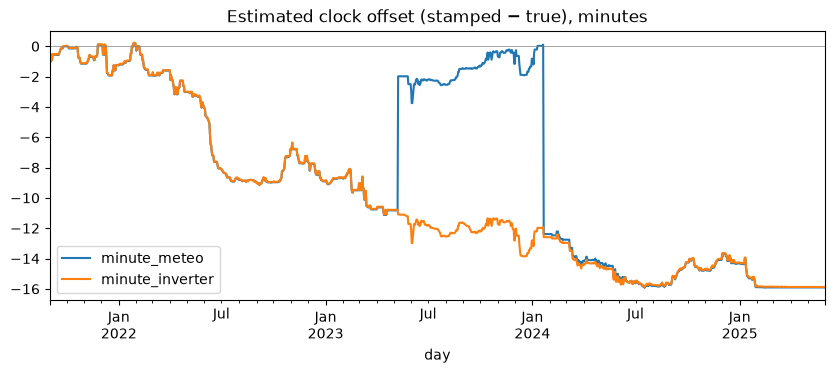

In [1]:
import json

import pandas as pd
from IPython.display import Image, display

from solarpv.config.paths import AUDIT_DIR, CONFIGS_DIR, PROCESSED_DIR

offsets = pd.read_csv(CONFIGS_DIR / "clock_offsets.csv", parse_dates=["day"])
ax = offsets.set_index("day")[["minute_meteo", "minute_inverter"]].plot(
    figsize=(10, 3.5), title="Estimated clock offset (stamped − true), minutes")
ax.axhline(0, color="grey", lw=0.5)
offsets[["minute_meteo", "minute_inverter"]].describe().round(2)

**What it shows.** The daily offset of each logger's clock, stamped time minus true time:
the meteorological logger (irradiance, temperatures) and the inverter logger (power). The largest
offset is -15.9 minutes. The steps are resynchronisations:
2023-05-09, 2024-01-21.

**How it was measured (OP-09).** The meteo clock from the fit of the in-plane sensor to the
clear-sky irradiance on clear days; the inverter clock relative to the meteo clock from the
cross-correlation of minute-to-minute changes of DC power and irradiance. A 31-day rolling median
within the segments between steps.

In [2]:
monthly = pd.read_csv(AUDIT_DIR / "clock_drift_2026-10-14"
                      / "monthly_minute_before_after.csv")
monthly[["day", "tau_met", "tau_met_after", "delta", "delta_after"]].tail(12)

,day,tau_met,tau_met_after,delta,delta_after
31,2024-04,-14.11,-0.33,-0.21,-0.18
32,2024-05,-14.47,-0.34,-0.19,0.21
33,2024-06,-15.52,0.52,0.03,0.42
34,2024-07,-15.84,0.15,0.07,0.07
35,2024-08,-15.72,-0.12,0.05,0.05
36,2024-09,-14.77,-0.43,0.03,0.06
37,2024-10,-14.53,-0.77,0.02,0.02
38,2024-11,-14.71,-1.03,0.06,0.06
39,2024-12,-14.00,-0.91,0.06,0.06
40,2025-01,-15.20,-1.32,0.05,0.05


**What it shows.** Per month, the residual offset before and after the correction
(`tau_met`: meteo clock against the sun; `delta`: inverter clock against meteo clock).

**What it means.** After the correction no monthly median exceeds 1.74
minutes for the meteo clock and 0.7 minutes between the loggers; the absolute
uncertainty is about ±2 minutes. Correcting the clocks costs a few minutes at the edges of the
data (188–291 minutes per tag), shifted out of the range.

## 2. The second data source of 2025

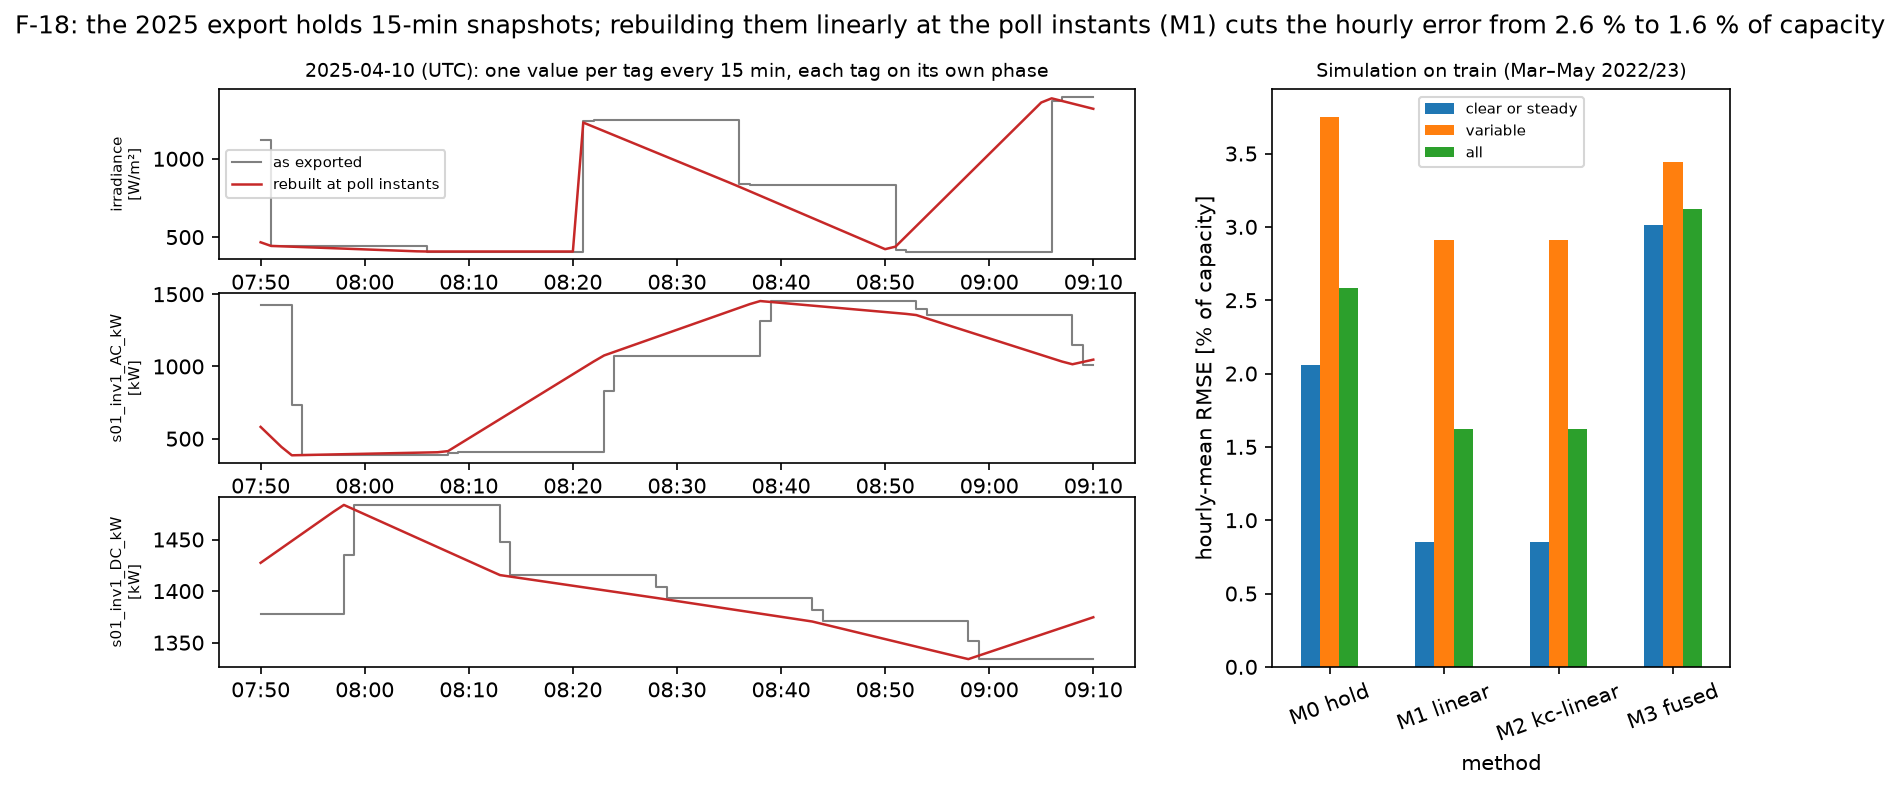

In [3]:
display(Image("../outputs/03_eda/figures/fig04_polled.png", width=900))

**What it shows.** From 2025-02-26 (era from
2025-03-03), most minutes repeat the previous value: each tag is a snapshot
taken every 15 minutes on its own phase and held until the next one.

**What it means.** An hourly mean of held snapshots lags by about 7.5 minutes and is built from
four samples. The rebuild detects the source of every tag and hour (OP-10), puts each sample
back at its poll instant on its own clock, and interpolates between samples (D-20).

In [4]:
pd.read_csv(AUDIT_DIR / "polled_reconstruction_2026-10-15" / "summary.csv")

,days,method,n_hours,rmse_kW,rmse_pct_capacity,bias_kW,p95_abs_kW
0,all,M0 hold,2194,88.9,2.58,-1.9,168.7
1,all,M1 linear,2194,55.8,1.62,-1.0,111.8
2,all,M2 kc-linear,2194,55.8,1.62,-0.6,110.9
3,all,M3 fused,2194,107.7,3.12,-15.3,203.9
4,clear or steady,M0 hold,1658,71.0,2.06,-0.9,109.7
5,clear or steady,M1 linear,1658,29.2,0.85,-0.3,54.1
6,clear or steady,M2 kc-linear,1658,29.3,0.85,0.1,54.0
7,clear or steady,M3 fused,1658,103.9,3.01,-11.7,151.8
8,variable,M0 hold,536,129.3,3.75,-4.9,263.0
9,variable,M1 linear,536,100.5,2.91,-3.3,206.9


**What it shows.** The reconstruction methods were compared by simulating the 2025
polling on train data, where the true minutes are known: hold the snapshot (M0), linear
interpolation (M1), interpolation of the clear-sky index (M2) and a fused source (M3).

**What it means.** On all simulated hours linear interpolation has an hourly error of
1.62 % of capacity against
2.58 % for holding the snapshot. M2 is no better.
**Decision (D-21):** M1, chosen on train before any model result. The test months that come
from this source are also reported separately (stage 8).

## 3. Hourly means

In [5]:
hourly = pd.read_parquet(PROCESSED_DIR / "04_preprocess" / "scada_1H_utc.parquet",
                         columns=["site_total_AC_kW", "irradiance"])
manifest = json.loads((PROCESSED_DIR / "04_preprocess" / "preprocess_manifest.json")
                      .read_text(encoding="utf-8"))
print(len(hourly), "hours | rule:", manifest["hourly_rule"])
hourly.describe().round(1)

32856 hours | rule: left-labelled mean, valid if >= 45/60 minutes


,site_total_AC_kW,irradiance
count,32856.0,32856.0
mean,700.1,275.3
std,920.7,364.1
min,0.0,-2.4
25%,0.0,0.0
50%,24.0,10.1
75%,1511.5,567.6
max,3271.9,1247.4


**What it shows.** 32,856 hourly rows, labelled at the start of the hour (row t
covers t to t+1 h), valid when at least 45 of the 60 minutes are present. No hour of the target
or of the main sensors is missing (0 empty hours).

**What it means.** The site total peaks at 3,271.9 kW in one hour, above its 99.99th
percentile (2,909.5 kW). Such hours still contain logger spikes; they are
removed in stage 5 by documented rules, not here.

**Next stage.** Stage 5 (`04_cleaning.ipynb`) applies the cleaning rules and the operation flags.

**Reproduce.** `python scripts/estimate_clock_drift.py`, `python -m solarpv.data.preprocess`, then
`python scripts/make_preprocessing_notebook.py`.